# 03 · Agricultural EDA | 2021–2025

**Goal.** Reproducible exploratory analysis of agricultural production (29-сг) and production costs / inventory movements (50-сг). This notebook builds **descriptive evidence** for subsequent *prescriptive analytics and warehouse optimization*, rather than fitting forecasting models to five annual observations.

**Inputs:** Outputs of notebooks `01_agriculture_pdf_extraction.ipynb` and `02_agriculture_costs_inventory.ipynb`. No PDF is required for this notebook. All published amounts should be considered **unverified until cross-checked with the original reports**.

**Cautions:** 29-сг includes aggregate crop rows that must not be summed with their constituent crops; 50-сг uses different row-code families; the `agriculture_panel.csv` crop labels are based on a manually curated crosswalk; derived closing stock requires complete reported opening/inflow/outflow. Missing (`NaN`) is **not** zero. Monetary trends are *nominal UAH*, not inflation-adjusted.

## 0 · Environment and input paths

In [1]:
%pip -q install "pandas>=2.0,<3" "numpy>=1.26,<3" "matplotlib>=3.7" "seaborn>=0.12" "openpyxl>=3.1"


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 5), "figure.dpi": 110})

cwd = Path.cwd()
ROOT = cwd.parent if cwd.name == "notebooks" else cwd
DATA = ROOT / "data" / "agriculture" / "processed"
OUTPUT = ROOT / "outputs" / "agriculture_eda"
OUTPUT.mkdir(parents=True, exist_ok=True)
required = ["crop_production.csv", "production_costs.csv", "inventory_flows.csv", "agriculture_panel.csv"]
missing = [p for p in required if not (DATA / p).exists()]
if missing:
    raise FileNotFoundError(f"Missing files in {DATA}: {missing}. Run notebooks 01 and 02 locally first.")

def read_data(filename, **kwargs):
    return pd.read_csv(DATA / filename, encoding="utf-8-sig", **kwargs)

production = read_data("crop_production.csv", dtype={"crop_code": "string"})
cost = read_data("production_costs.csv", dtype={"row_code": "string"})
inv = read_data("inventory_flows.csv", dtype={"row_code": "string"})
panel = read_data("agriculture_panel.csv")
qa_path = DATA / "agriculture_qa.csv"
qa = read_data("agriculture_qa.csv", dtype={"row_code": "string"}) if qa_path.exists() else pd.DataFrame()
for frame in (production, cost, inv, panel):
    frame["year"] = pd.to_numeric(frame["year"], errors="raise").astype(int)
print("Root:", ROOT, "\nInput:", DATA, "\nOutput:", OUTPUT)
print("Loaded rows:", {"production": len(production), "cost": len(cost), "inventory": len(inv), "joined panel": len(panel)})

Root: /Users/margopaduchak/Desktop/прогнози/forecasting-and-decision-optimization 
Input: /Users/margopaduchak/Desktop/прогнози/forecasting-and-decision-optimization/data/agriculture/processed 
Output: /Users/margopaduchak/Desktop/прогнози/forecasting-and-decision-optimization/outputs/agriculture_eda
Loaded rows: {'production': 475, 'cost': 38, 'inventory': 52, 'joined panel': 30}


## 1 · Data inventory, missingness and trust checks

Audit the *coverage* first. Blank/`-`/`х` in reports is represented as missing; count missing values rather than replacing them with zeros. Inventory and cost totals are not automatically treated as independent crop categories.

In [3]:
datasets = {"production_29sg": production, "cost_50sg": cost, "inventory_50sg": inv, "crosswalk_panel": panel}
coverage = pd.concat({name: df.groupby("year").size() for name, df in datasets.items()}, axis=1).fillna(0).astype(int)
display(coverage)
key_cols = {
    "production_29sg": ["sown_area_ha", "harvested_area_ha", "harvest_tonnes", "yield_tonnes_per_ha"],
    "cost_50sg": ["production_cost_k_uah", "direct_materials_k_uah", "direct_labor_k_uah"],
    "inventory_50sg": ["opening_stock_tonnes", "inflow_tonnes", "outflow_tonnes", "ending_stock_derived_tonnes"],
    "crosswalk_panel": ["production_cost_k_uah", "ending_stock_derived_tonnes"],
}
missingness = pd.DataFrame([{"dataset": name, "field": col,
    "missing_count": int(df[col].isna().sum()), "missing_percent": round(100 * df[col].isna().mean(), 1)}
    for name, df in datasets.items() for col in key_cols[name] if col in df.columns])
display(missingness)
print("50-сг extraction QA entries:", len(qa))
if not qa.empty:
    display(qa[[c for c in ["severity", "dataset", "year", "row_code", "issue", "detail"] if c in qa.columns]])
# Assert that upstream key uniqueness is still intact.
for df, code, label in [(production, "crop_code", "29-сг"), (cost, "row_code", "50-сг cost"), (inv, "row_code", "50-сг inventory")]:
    duplicates = df.duplicated(["year", code], keep=False)
    print(f"{label} duplicate (year, code) records: {int(duplicates.sum())}")
    if duplicates.any(): display(df.loc[duplicates, ["year", code]].head(15))
if "_merge" in panel:
    print("Crosswalk merge status:", panel["_merge"].value_counts(dropna=False).to_dict())

,production_29sg,cost_50sg,inventory_50sg,crosswalk_panel
year,,,,
2021,93,6,9,6
2022,91,7,9,6
2023,97,8,11,6
2024,97,9,12,6
2025,97,8,11,6


,dataset,field,missing_count,missing_percent
0,production_29sg,sown_area_ha,437,92.0
1,production_29sg,harvested_area_ha,440,92.6
2,production_29sg,harvest_tonnes,456,96.0
3,production_29sg,yield_tonnes_per_ha,456,96.0
4,cost_50sg,production_cost_k_uah,0,0.0
5,cost_50sg,direct_materials_k_uah,0,0.0
6,cost_50sg,direct_labor_k_uah,0,0.0
7,inventory_50sg,opening_stock_tonnes,2,3.8
8,inventory_50sg,inflow_tonnes,0,0.0
9,inventory_50sg,outflow_tonnes,0,0.0


50-сг extraction QA entries: 2


,severity,dataset,year,row_code,issue,detail
0,warning,inventory,2021,3012,missing first numeric field,opening_stock_centners
1,warning,inventory,2024,3014,missing first numeric field,opening_stock_centners


29-сг duplicate (year, code) records: 0
50-сг cost duplicate (year, code) records: 0
50-сг inventory duplicate (year, code) records: 0
Crosswalk merge status: {'both': 30}


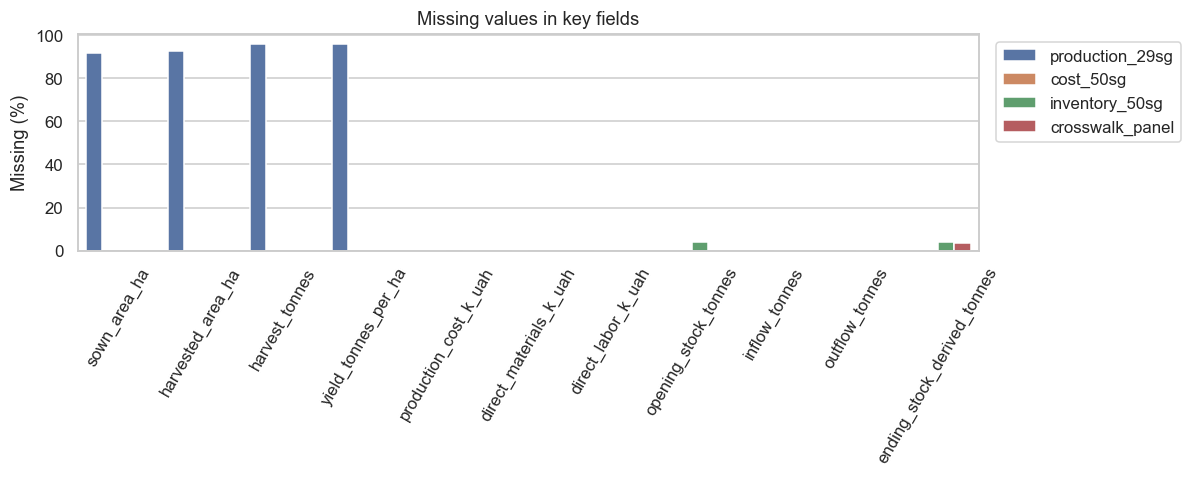

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=missingness, x="field", y="missing_percent", hue="dataset", ax=ax)
ax.set(title="Missing values in key fields", xlabel="", ylabel="Missing (%)")
ax.tick_params(axis="x", labelrotation=60)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
fig.savefig(OUTPUT / "01_missingness.png", bbox_inches="tight")
plt.show()

## 2 · Crop production and harvested area (29-сг)

**Avoid double counting:** filter rows marked `potential_aggregate`, and omit row code `0030` (grain total) as a further safeguard. A sum across *all* crops would also potentially double-count overlapping subcategories: focus on explicit *leaf crop codes* and review their labels. Here we keep the auditable, non-aggregate crop rows as extracted and report their observed coverage. This is **not** the enterprise's all-crop total.

In [5]:
flag = production["potential_aggregate"].fillna(False).astype(str).str.lower().eq("true")
leaf = production.loc[~flag & production["crop_code"].ne("0030")].copy()
for col in ["harvest_tonnes", "sown_area_ha", "harvested_area_ha", "yield_tonnes_per_ha"]:
    leaf[col] = pd.to_numeric(leaf[col], errors="coerce")
leaf = leaf.loc[leaf["harvest_tonnes"].gt(0) & leaf["harvested_area_ha"].gt(0)].copy()
leaf["crop_display"] = leaf["crop_name_raw"].str.replace(r"(?<=[а-яіїєґ])(?=[А-ЯІЇЄҐ])", " ", regex=True)
print("Nonaggregate rows with positive harvest:", len(leaf))
print("Note: these are observable selected leaf rows, not a validated all-crop enterprise total.")
display(leaf[["year", "crop_code", "crop_display", "harvested_area_ha", "harvest_tonnes", "yield_tonnes_per_ha"]].head(20))
# Crop code is stable across the supplied 29-сг years; prefer it to inconsistently-spaced names.
by_crop = leaf.groupby(["crop_code", "crop_display"], as_index=False).agg(total_observed_tonnes=("harvest_tonnes", "sum"), years_observed=("year", "nunique"))
top_codes = by_crop.sort_values("total_observed_tonnes", ascending=False).head(8)["crop_code"].tolist()
subset = leaf.loc[leaf.crop_code.isin(top_codes)].copy()
labels = subset.sort_values("year").groupby("crop_code")["crop_display"].first().to_dict()
subset["crop_label"] = subset.crop_code.map(lambda x: f"{labels[x]} ({x})")

Nonaggregate rows with positive harvest: 15
Note: these are observable selected leaf rows, not a validated all-crop enterprise total.


,year,crop_code,crop_display,harvested_area_ha,harvest_tonnes,yield_tonnes_per_ha
0,2021,0050,Пшеницяозима,1100.0,8459.3,7.690273
2,2021,0110,Кукурудза,1600.0,19368.8,12.105500
4,2021,0140,Ячмiньярий,720.0,3784.5,5.256250
94,2022,0050,Пшеницяозима,1100.0,7203.5,6.548636
96,2022,0110,Кукурудза,700.0,6202.5,8.860714
98,2022,0140,Ячмiньярий,1100.0,6940.1,6.309182
185,2023,0050,Пшеницяозима,1400.0,11116.2,7.940143
187,2023,0110,Кукурудза,640.0,9109.7,14.233906
189,2023,0140,Ячміньярий,1495.0,8747.0,5.850836
282,2024,0050,Пшеницяозима,600.0,5696.8,9.494667


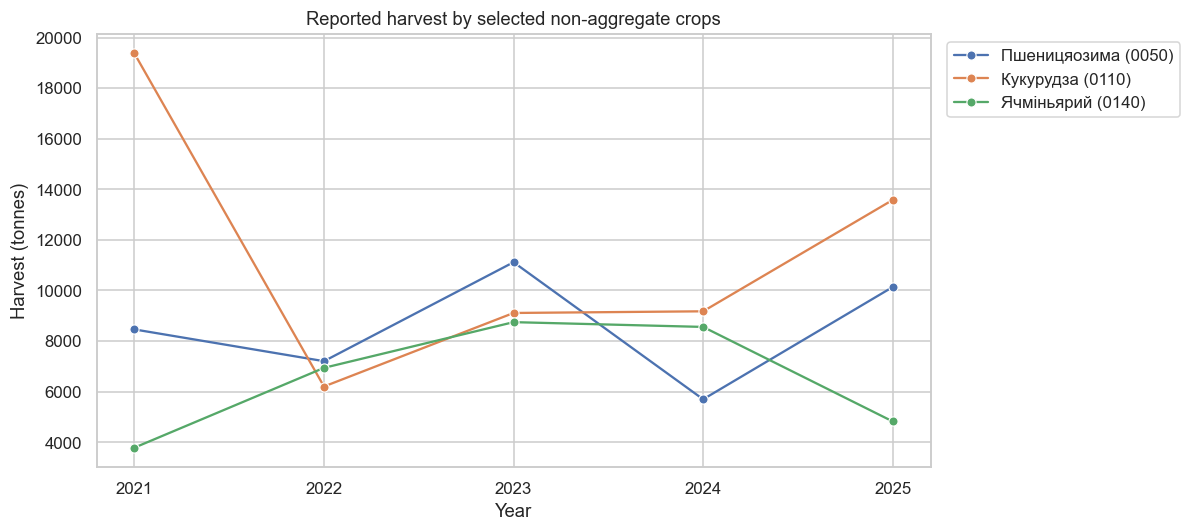

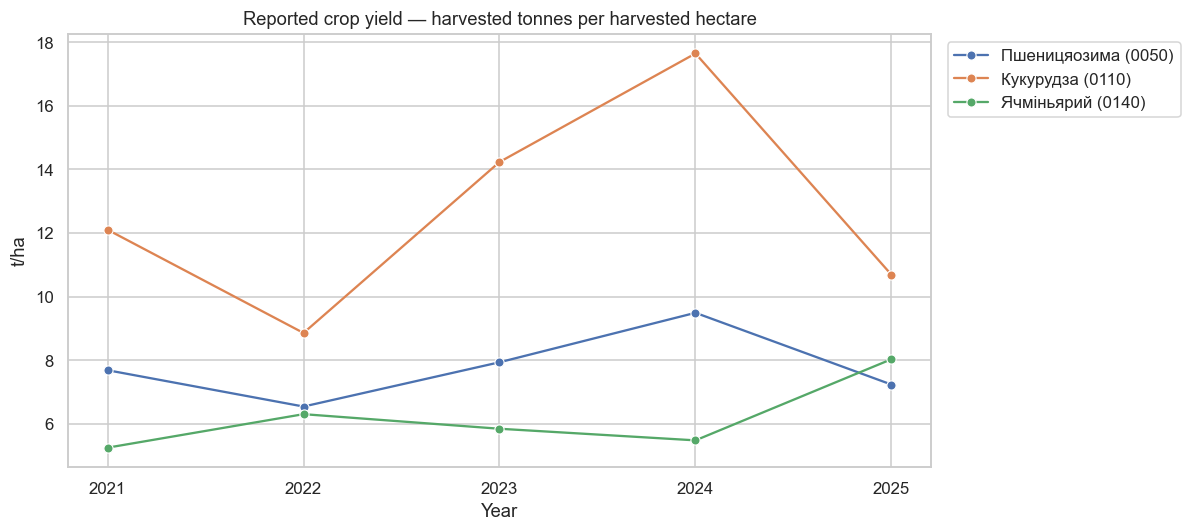

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=subset, x="year", y="harvest_tonnes", hue="crop_label", marker="o", ax=ax)
ax.set(title="Reported harvest by selected non-aggregate crops", xlabel="Year", ylabel="Harvest (tonnes)")
ax.set_xticks(sorted(production.year.unique()))
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); fig.savefig(OUTPUT / "02_harvest_by_crop.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=subset, x="year", y="yield_tonnes_per_ha", hue="crop_label", marker="o", ax=ax)
ax.set(title="Reported crop yield — harvested tonnes per harvested hectare", xlabel="Year", ylabel="t/ha")
ax.set_xticks(sorted(production.year.unique()))
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); fig.savefig(OUTPUT / "03_yield_by_crop.png", bbox_inches="tight"); plt.show()

## 3 · Cost composition (50-сг)

`production_cost_k_uah` is **thousands of hryvnias**. Do not mix it with UAH or treat values as inflation-adjusted. A stacked composition chart uses only primary, mutually exclusive cost categories (materials, direct labor, other direct costs/overhead); their subcomponents must not be added again.

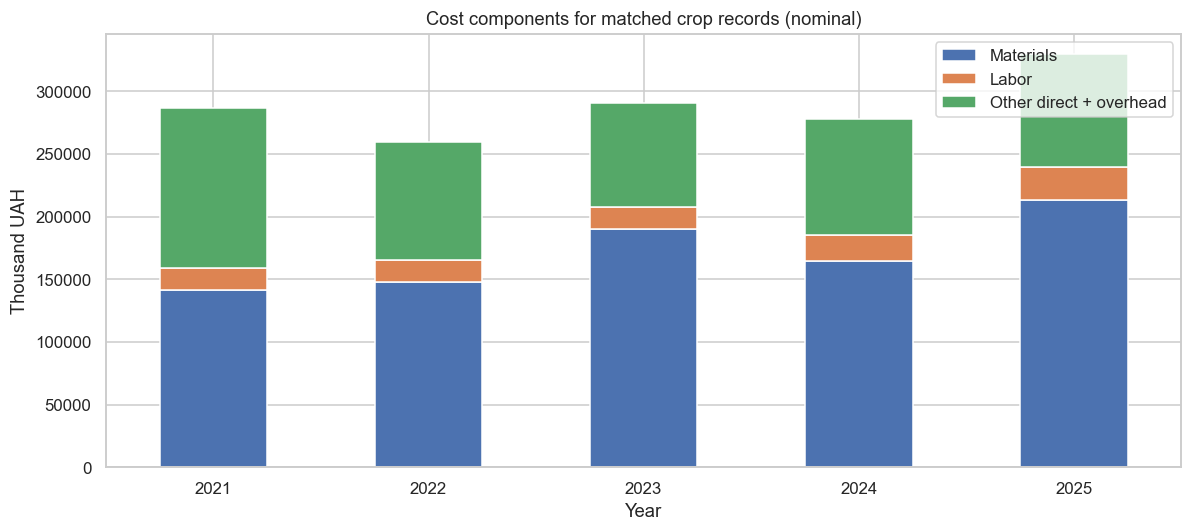

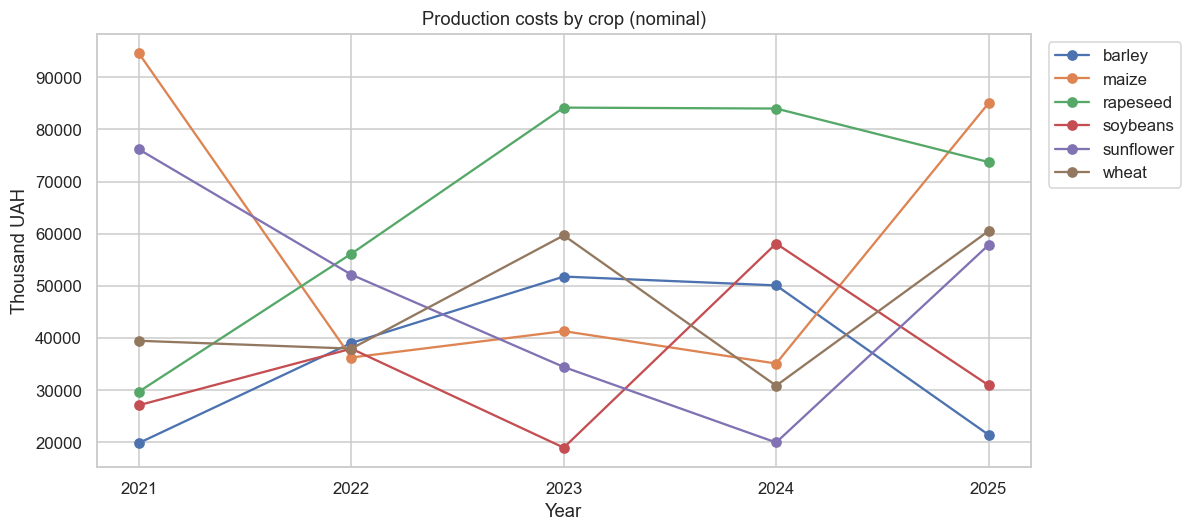

In [7]:
cost_components = ["direct_materials_k_uah", "direct_labor_k_uah", "other_direct_and_overhead_k_uah"]
# use the crop-level crosswalk subset from notebook 02; it intentionally excludes aggregate cost rows.
cost_crop = panel[["year", "crop", "production_cost_k_uah"] + cost_components].copy()
for col in ["production_cost_k_uah"] + cost_components:
    cost_crop[col] = pd.to_numeric(cost_crop[col], errors="coerce")
annual_cost = cost_crop.groupby("year")[cost_components].sum(min_count=1).sort_index()
ax = annual_cost.rename(columns={"direct_materials_k_uah":"Materials", "direct_labor_k_uah":"Labor", "other_direct_and_overhead_k_uah":"Other direct + overhead"}).plot(kind="bar", stacked=True, figsize=(11, 5))
ax.set(title="Cost components for matched crop records (nominal)", ylabel="Thousand UAH", xlabel="Year")
plt.xticks(rotation=0); plt.tight_layout(); ax.figure.savefig(OUTPUT / "04_cost_structure.png", bbox_inches="tight"); plt.show()

cost_pivot = cost_crop.pivot(index="year", columns="crop", values="production_cost_k_uah").sort_index()
ax = cost_pivot.plot(marker="o", figsize=(11, 5))
ax.set(title="Production costs by crop (nominal)", ylabel="Thousand UAH", xlabel="Year")
ax.set_xticks(cost_pivot.index)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); ax.figure.savefig(OUTPUT / "05_costs_by_crop.png", bbox_inches="tight"); plt.show()

In [8]:
# Composition as percentages: only rows with reported positive parent cost and all three components.
valid_cost = cost_crop.dropna(subset=["production_cost_k_uah"] + cost_components)
valid_cost = valid_cost.loc[valid_cost.production_cost_k_uah.gt(0)].copy()
valid_cost["components_sum"] = valid_cost[cost_components].sum(axis=1)
valid_cost["cost_gap_pct"] = 100 * (valid_cost["production_cost_k_uah"] - valid_cost["components_sum"]) / valid_cost["production_cost_k_uah"]
print("Cost rows with fully observed top-level components:", len(valid_cost), "/", len(cost_crop))
if len(valid_cost):
    display(valid_cost.groupby("year")["cost_gap_pct"].agg(["count", "mean", "max"]).round(2))
else: print("Insufficient complete component rows for cost consistency comparison.")

Cost rows with fully observed top-level components: 30 / 30


,count,mean,max
year,,,
2021,6,-0.0,0.0
2022,6,0.0,0.0
2023,6,-0.0,0.0
2024,6,-0.0,0.0
2025,6,0.0,0.0


## 4 · Inventory movements and available closing stock (50-сг)

`ending_stock_derived_tonnes = opening + inflow − outflow`. It is **not directly reported closing stock**. Only interpret it when all three inputs are present; a missing value is not treated as zero. All comparisons below use the documented crop crosswalk in `agriculture_panel.csv`.

Complete inventory balances: 29 / 30


,year,crop,opening_stock_tonnes,inflow_tonnes,outflow_tonnes,ending_stock_derived_tonnes,complete_balance
0,2021,barley,717.7,3899.5,2566.5,2050.7,True
1,2021,maize,11732.6,19928.0,12154.6,19506.0,True
2,2021,rapeseed,NaN,2651.2,2644.5,NaN,False
3,2021,soybeans,2238.6,2618.9,2271.0,2586.5,True
4,2021,sunflower,1672.8,6929.6,2741.2,5861.2,True
5,2021,wheat,4146.9,8765.4,5029.0,7883.3,True
6,2022,barley,2050.7,7127.1,8755.2,422.6,True
7,2022,maize,19506.0,6256.2,15724.1,10038.1,True
8,2022,rapeseed,6.7,4407.8,4413.8,0.7,True
9,2022,soybeans,2586.5,3449.0,973.9,5061.6,True


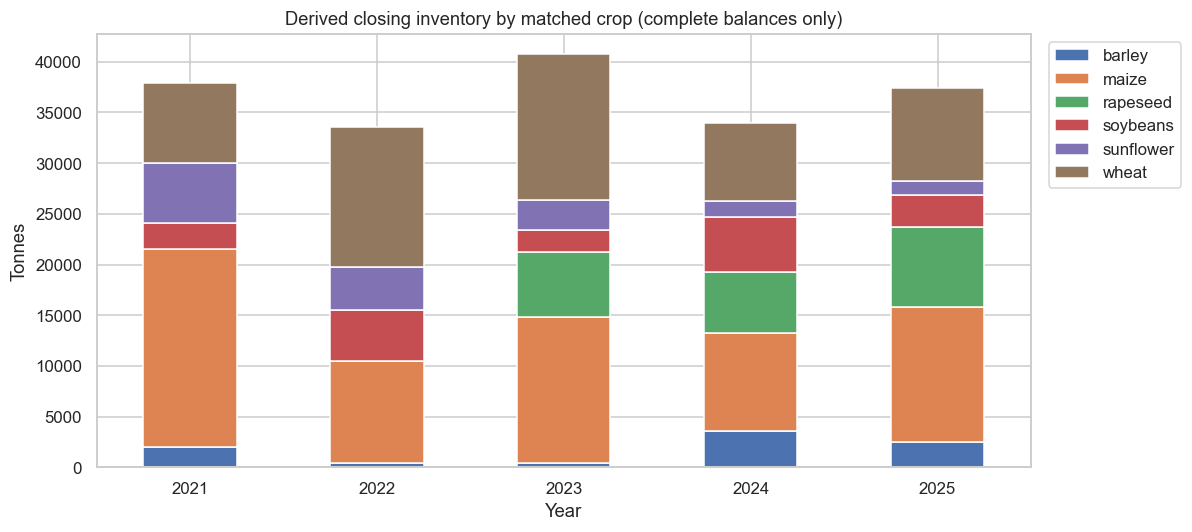

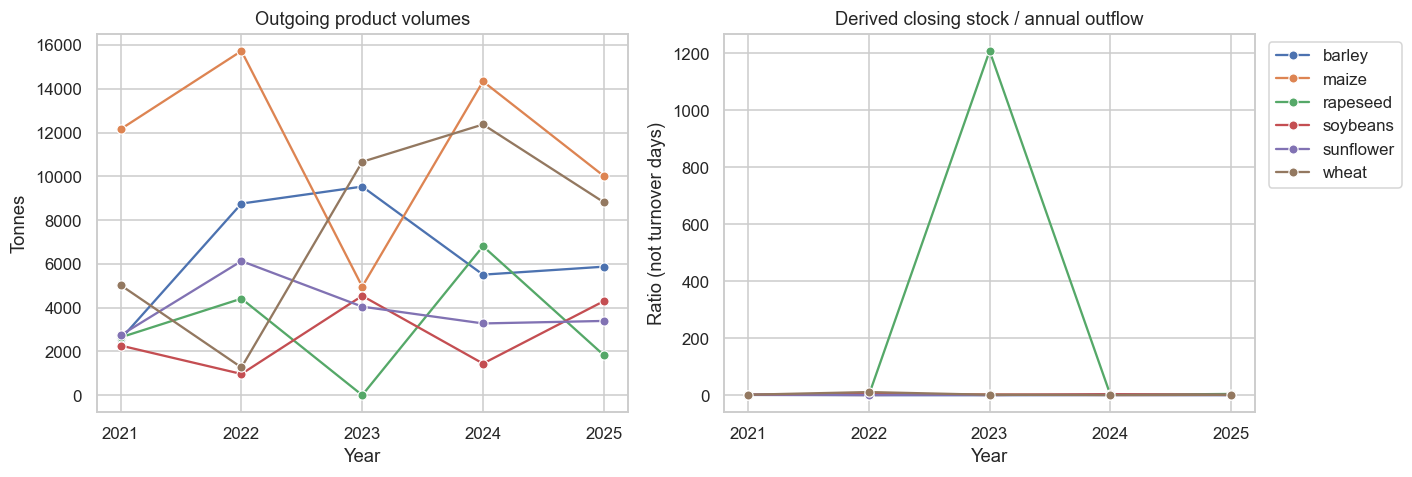

In [9]:
stock_fields = ["opening_stock_tonnes", "inflow_tonnes", "outflow_tonnes", "ending_stock_derived_tonnes"]
stock = panel[["year", "crop"] + stock_fields].copy()
for col in stock_fields: stock[col] = pd.to_numeric(stock[col], errors="coerce")
stock["complete_balance"] = stock[["opening_stock_tonnes", "inflow_tonnes", "outflow_tonnes"]].notna().all(axis=1)
stock.loc[~stock.complete_balance, "ending_stock_derived_tonnes"] = np.nan
stock["expected_closing"] = stock.opening_stock_tonnes + stock.inflow_tonnes - stock.outflow_tonnes
stock["balance_error_tonnes"] = stock.ending_stock_derived_tonnes - stock.expected_closing
stock["stock_outflow_ratio"] = np.where(stock.outflow_tonnes.gt(0), stock.ending_stock_derived_tonnes / stock.outflow_tonnes, np.nan)
stock["outflow_to_available_ratio"] = np.where((stock.opening_stock_tonnes + stock.inflow_tonnes).gt(0), stock.outflow_tonnes / (stock.opening_stock_tonnes + stock.inflow_tonnes), np.nan)
print("Complete inventory balances:", int(stock.complete_balance.sum()), "/", len(stock))
display(stock[["year", "crop"] + stock_fields + ["complete_balance"]].head(20))

ending = stock.pivot(index="year", columns="crop", values="ending_stock_derived_tonnes").sort_index()
ax=ending.plot(kind="bar", stacked=True, figsize=(11, 5))
ax.set(title="Derived closing inventory by matched crop (complete balances only)", xlabel="Year", ylabel="Tonnes")
plt.xticks(rotation=0); ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); ax.figure.savefig(OUTPUT / "06_closing_stocks.png", bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.lineplot(data=stock, x="year", y="outflow_tonnes", hue="crop", marker="o", ax=axes[0], legend=False)
axes[0].set(title="Outgoing product volumes", ylabel="Tonnes", xlabel="Year")
sns.lineplot(data=stock, x="year", y="stock_outflow_ratio", hue="crop", marker="o", ax=axes[1])
axes[1].set(title="Derived closing stock / annual outflow", ylabel="Ratio (not turnover days)", xlabel="Year")
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left")
for ax in axes: ax.set_xticks(sorted(stock.year.unique()))
plt.tight_layout(); fig.savefig(OUTPUT / "07_inventory_outflows_and_ratio.png", bbox_inches="tight"); plt.show()

## 5 · Warehouse-relevant descriptive insights

The purpose is to identify candidate products for capacity allocation and scenario testing. **No warehouse capacity, actual storage costs, market prices or within-year seasonality are present here.** Therefore neither an optimal inventory policy nor a profit forecast follows from these charts alone.

,crop,opening_stock_tonnes,inflow_tonnes,outflow_tonnes,ending_stock_derived_tonnes,stock_outflow_ratio,inventory_share_pct,complete_balance
25,maize,9638.0,13673.9,10014.7,13297.2,1.33,35.55,True
29,wheat,7668.3,10309.5,8816.4,9161.4,1.04,24.50,True
26,rapeseed,6086.9,3599.2,1834.5,7851.6,4.28,20.99,True
27,soybeans,5427.9,2042.6,4299.1,3171.4,0.74,8.48,True
24,barley,3576.0,4821.4,5872.8,2524.6,0.43,6.75,True
28,sunflower,1529.5,3258.8,3395.0,1393.3,0.41,3.73,True


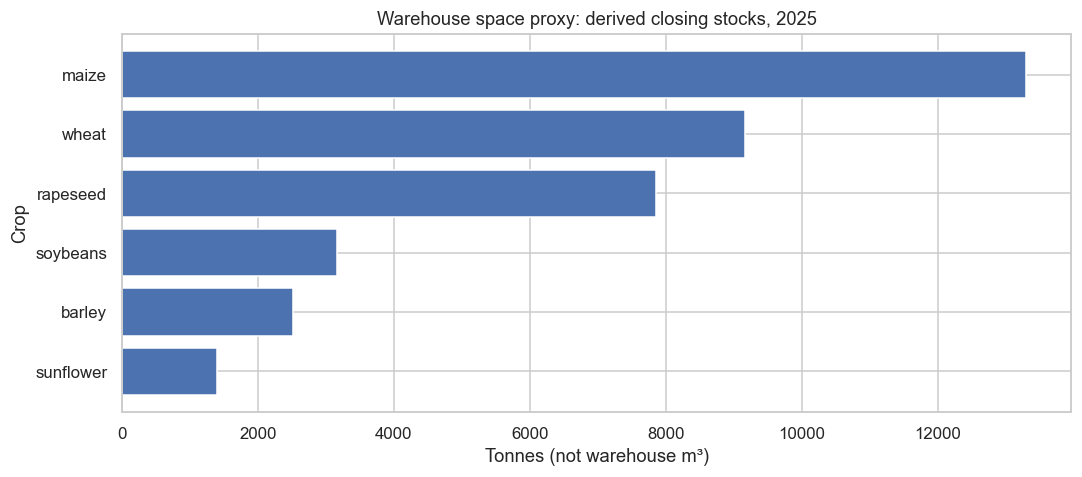

In [10]:
latest_year = int(stock.year.max())
latest = stock.loc[stock.year.eq(latest_year)].copy()
latest["inventory_share_pct"] = (100 * latest.ending_stock_derived_tonnes /
    latest.ending_stock_derived_tonnes.clip(lower=0).sum(min_count=1)) if latest.ending_stock_derived_tonnes.clip(lower=0).sum(min_count=1) > 0 else np.nan
latest_view = latest[["crop", "opening_stock_tonnes", "inflow_tonnes", "outflow_tonnes", "ending_stock_derived_tonnes", "stock_outflow_ratio", "inventory_share_pct", "complete_balance"]]
display(latest_view.sort_values("ending_stock_derived_tonnes", ascending=False).round(2))

ranked = latest.dropna(subset=["ending_stock_derived_tonnes"]).sort_values("ending_stock_derived_tonnes", ascending=False)
if not ranked.empty:
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.barh(ranked["crop"], ranked["ending_stock_derived_tonnes"])
    ax.invert_yaxis()
    ax.set(title=f"Warehouse space proxy: derived closing stocks, {latest_year}", ylabel="Crop", xlabel="Tonnes (not warehouse m³)")
    plt.tight_layout(); fig.savefig(OUTPUT / "08_latest_inventory_ranking.png", bbox_inches="tight"); plt.show()

# For model planning: cost per tonne calculated ONLY where the 29-сг code mapping is independently verified.
# The current notebook deliberately does not divide 50-сг cost by 29-сг harvest with an unverified crop match.

## 6 · Descriptive conclusions and reproducible exports

Generate short, calculation-backed observations. The notes are *descriptive*, not causal: a change in costs cannot be attributed to one factor without additional information (inflation, prices, input rates, operating changes). Each insight should be interpreted with the upstream QA and manual report review.

In [11]:
insights=[]
insights.append(f"Source coverage: {production.year.nunique()} annual years for 29-сг and {panel.year.nunique()} for 50-сг panel; no within-year seasonality can be estimated.")
insights.append(f"Inventory: {int(stock.complete_balance.sum())}/{len(stock)} crosswalk records have all three inputs for an arithmetic closing stock estimate.")
if not ranked.empty:
    r=ranked.iloc[0]
    insights.append(f"In {latest_year}, the largest derived closing stock among the matched crops is {r['crop']} ({r['ending_stock_derived_tonnes']:,.1f} tonnes).")
if len(valid_cost):
    insights.append(f"Production cost decomposition has {len(valid_cost)} complete crop-year records; values are nominal thousand UAH.")
if not qa.empty: insights.append(f"The upstream extraction QA contains {len(qa)} flagged record(s); inspect them before modeling.")
insights.append("Warehouse capacity and storage costs are NOT observed in these files; all optimization scenarios using them must label assumptions.")
for item in insights: display(Markdown('- ' + item))

coverage.to_csv(OUTPUT / "data_coverage.csv", encoding="utf-8-sig")
missingness.to_csv(OUTPUT / "missingness.csv", index=False, encoding="utf-8-sig")
latest_view.to_csv(OUTPUT / "latest_inventory_metrics.csv", index=False, encoding="utf-8-sig")
stock.to_csv(OUTPUT / "inventory_eda_metrics.csv", index=False, encoding="utf-8-sig")
with (OUTPUT / "eda_summary.md").open("w", encoding="utf-8") as f:
    f.write("# Agricultural EDA — summary\n\n" + "\n".join('- ' + x for x in insights) + "\n")
print("Saved", len(list(OUTPUT.glob('*.png'))), "charts and",len(list(OUTPUT.glob('*.csv'))), "tables to",OUTPUT)

- Source coverage: 5 annual years for 29-сг and 5 for 50-сг panel; no within-year seasonality can be estimated.

- Inventory: 29/30 crosswalk records have all three inputs for an arithmetic closing stock estimate.

- In 2025, the largest derived closing stock among the matched crops is maize (13,297.2 tonnes).

- Production cost decomposition has 30 complete crop-year records; values are nominal thousand UAH.

- The upstream extraction QA contains 2 flagged record(s); inspect them before modeling.

- Warehouse capacity and storage costs are NOT observed in these files; all optimization scenarios using them must label assumptions.

Saved 8 charts and 4 tables to /Users/margopaduchak/Desktop/прогнози/forecasting-and-decision-optimization/outputs/agriculture_eda
